
Dataset: https://www.andyreiter.com/datasets/ 
https://www.usnews.com/best-colleges/rankings/national-universities 
https://nces.ed.gov/ipeds/datacenter/DataFiles.aspx?year=2024&sid=b6a4d888-22e4-45eb-b568-189d139610c2&rtid=1 (1st row dictionary and data)





In [ ]:
# data 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

UniversityRankings = pd.read_csv("UniversityRankings.csv")

UniversityRankings = UniversityRankings[['University Name','IPEDS','2027', '2026', '2025', '2024', '2023', '2022']]

Top50 = UniversityRankings[UniversityRankings['2022'] <= 50].copy()

# There are 6 schools tied for 49 in 2022 so top 54 schools were taken into account 

# Converts all numbers to integers
years = ['2022', '2023', '2024', '2025', '2026', '2027']
Top50[years] = Top50[years].apply(
    pd.to_numeric, errors='coerce'
).astype('Int64')


In [2]:
Top50.to_csv("Top50_Flourish.csv", index=False)

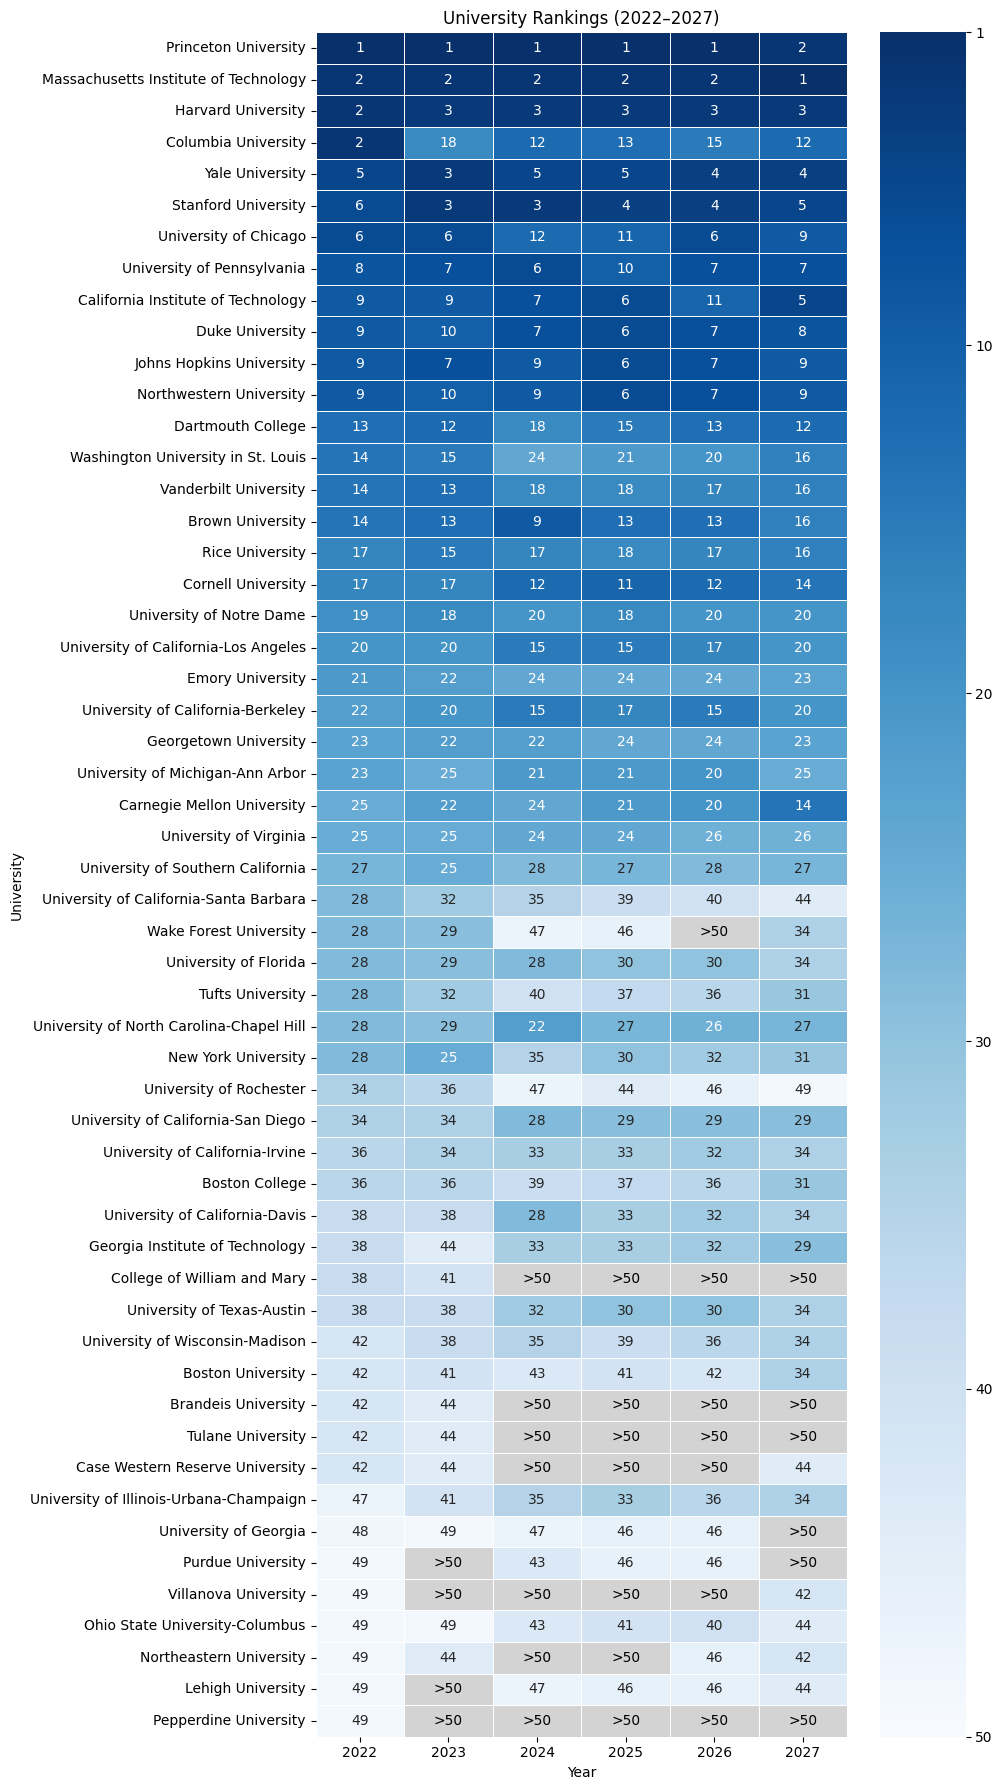

In [ ]:
# Note: this was not used from the article, and expanded to include more years 
# top 50 universities highlighted 
heatmap_data = Top50[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2022')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

# Filters >50
labels = heatmap_data.copy()
labels = labels.map(lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else '')
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

plt.figure(figsize=(10, 18))
ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5,
)

# flips legend upsidown (1 on top)
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

ax.set_facecolor('lightgrey')
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')
            
plt.title('University Rankings (2022–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()







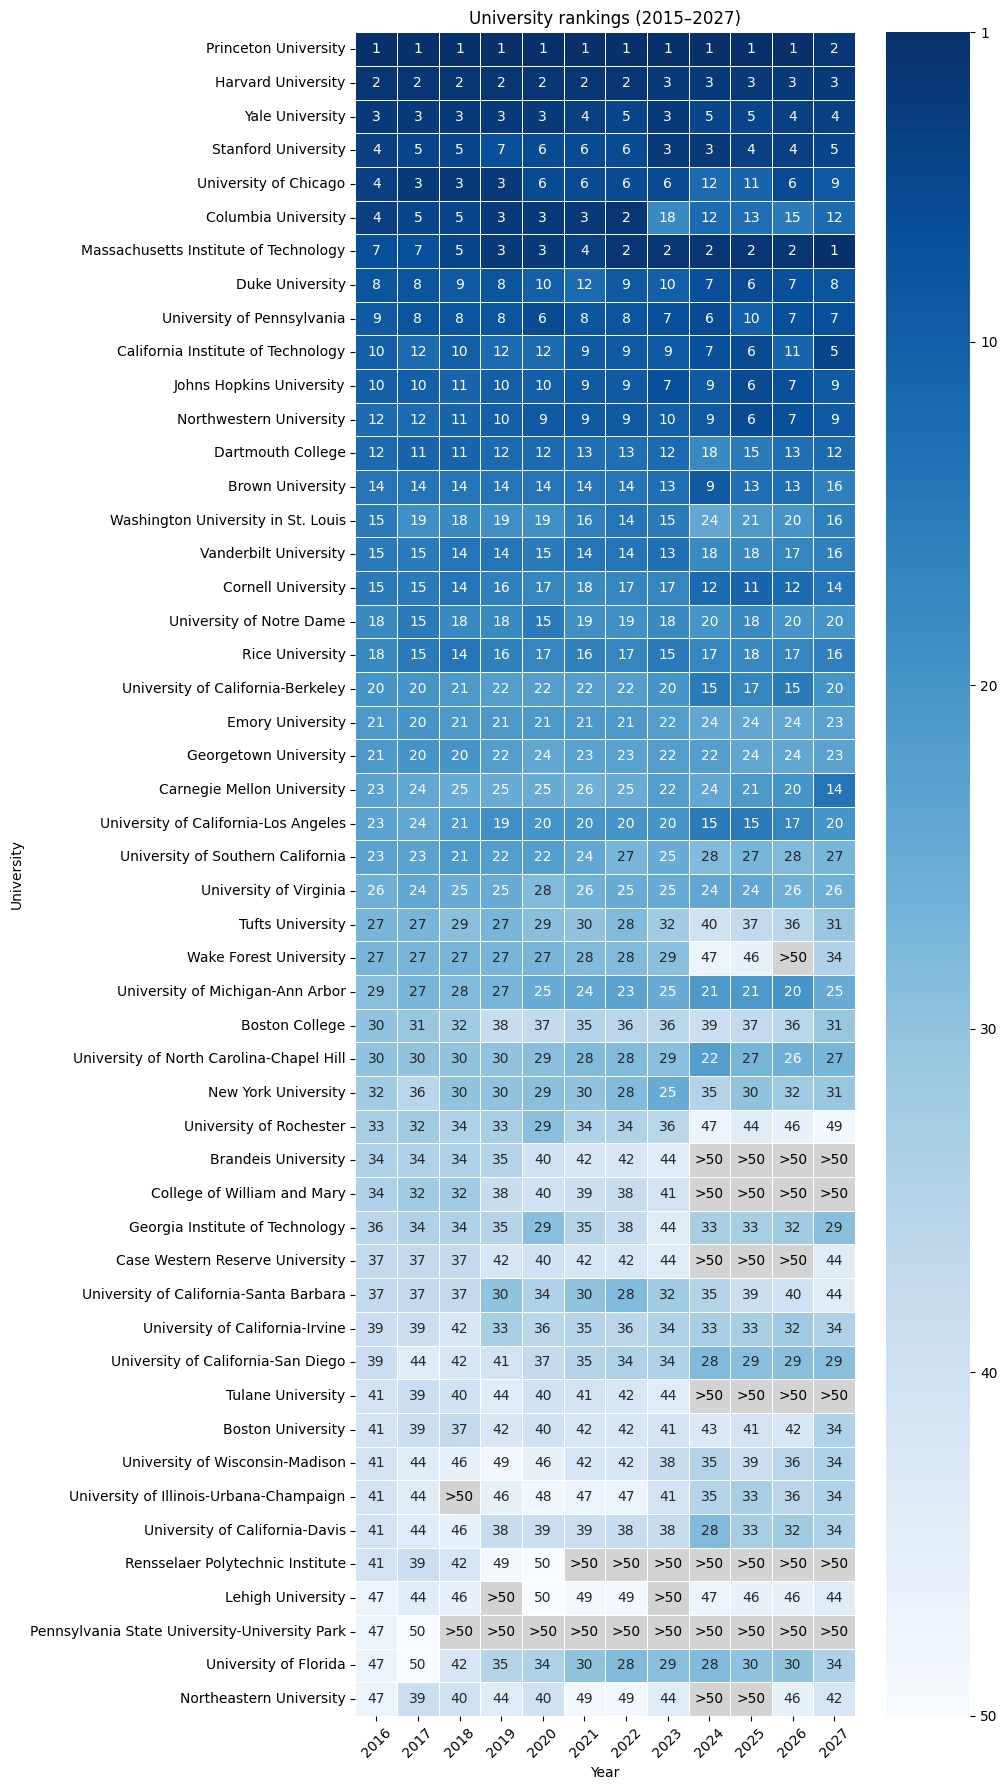

In [ ]:
# Note: this was used for the article and made into java script for publishing purposes  
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

UniversityRankings = pd.read_csv("UniversityRankings.csv")

UniversityRankings = UniversityRankings[['University Name','IPEDS','2027', '2026', '2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016']]

Top50 = UniversityRankings[UniversityRankings['2016'] <= 50].copy()

# There are 6 schools tied for 49 in 2022 so top 54 schools were taken into account 

# Converts all numbers to integers
years = ['2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', '2027']
Top50[years] = Top50[years].apply(
    pd.to_numeric, errors='coerce'
).astype('Int64')

# top 50 universities highlighted 
heatmap_data = Top50[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2016')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

# Filters >50
labels = heatmap_data.copy()
labels = labels.map(lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else '')
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

plt.figure(figsize=(10, 18))
ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5,
)

#flips legend upsidown (1 on top)
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

ax.set_facecolor('lightgrey')
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')
            
plt.title('University rankings (2015–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# Note: data was converted into this format to put into flourish for publishing purposes 

# Convert university names back into a column
flourish_data = heatmap_data.reset_index()

# Copy as tab-separated data
print(flourish_data.to_csv(index=False, sep='\t'))

University Name	2016	2017	2018	2019	2020	2021	2022	2023	2024	2025	2026	2027
Princeton University	1.0	1.0	1.0	1.0	1.0	1.0	1.0	1.0	1.0	1.0	1.0	2.0
Harvard University	2.0	2.0	2.0	2.0	2.0	2.0	2.0	3.0	3.0	3.0	3.0	3.0
Yale University	3.0	3.0	3.0	3.0	3.0	4.0	5.0	3.0	5.0	5.0	4.0	4.0
Stanford University	4.0	5.0	5.0	7.0	6.0	6.0	6.0	3.0	3.0	4.0	4.0	5.0
University of Chicago	4.0	3.0	3.0	3.0	6.0	6.0	6.0	6.0	12.0	11.0	6.0	9.0
Columbia University	4.0	5.0	5.0	3.0	3.0	3.0	2.0	18.0	12.0	13.0	15.0	12.0
Massachusetts Institute of Technology	7.0	7.0	5.0	3.0	3.0	4.0	2.0	2.0	2.0	2.0	2.0	1.0
Duke University	8.0	8.0	9.0	8.0	10.0	12.0	9.0	10.0	7.0	6.0	7.0	8.0
University of Pennsylvania	9.0	8.0	8.0	8.0	6.0	8.0	8.0	7.0	6.0	10.0	7.0	7.0
California Institute of Technology	10.0	12.0	10.0	12.0	12.0	9.0	9.0	9.0	7.0	6.0	11.0	5.0
Johns Hopkins University	10.0	10.0	11.0	10.0	10.0	9.0	9.0	7.0	9.0	6.0	7.0	9.0
Northwestern University	12.0	12.0	11.0	10.0	9.0	9.0	9.0	10.0	9.0	6.0	7.0	9.0
Dartmouth College	12.0	11.0	11.0	12.0	

In [ ]:
# Note: data was converted into this format to put into Datawrapper for publishing purposes

datawrapper_data = heatmap_data.reset_index().copy()

years = [str(year) for year in range(2016, 2028)]

for year in years:
    datawrapper_data[year] = datawrapper_data[year].apply(
        lambda x: '>50@@51' if pd.notna(x) and x > 50
        else str(int(x)) if pd.notna(x)
        else ''
    )

# Print tab-separated data for copying
print(datawrapper_data.to_csv(sep='\t', index=False))


University Name	2016	2017	2018	2019	2020	2021	2022	2023	2024	2025	2026	2027
Princeton University	1	1	1	1	1	1	1	1	1	1	1	2
Harvard University	2	2	2	2	2	2	2	3	3	3	3	3
Yale University	3	3	3	3	3	4	5	3	5	5	4	4
Stanford University	4	5	5	7	6	6	6	3	3	4	4	5
University of Chicago	4	3	3	3	6	6	6	6	12	11	6	9
Columbia University	4	5	5	3	3	3	2	18	12	13	15	12
Massachusetts Institute of Technology	7	7	5	3	3	4	2	2	2	2	2	1
Duke University	8	8	9	8	10	12	9	10	7	6	7	8
University of Pennsylvania	9	8	8	8	6	8	8	7	6	10	7	7
California Institute of Technology	10	12	10	12	12	9	9	9	7	6	11	5
Johns Hopkins University	10	10	11	10	10	9	9	7	9	6	7	9
Northwestern University	12	12	11	10	9	9	9	10	9	6	7	9
Dartmouth College	12	11	11	12	12	13	13	12	18	15	13	12
Brown University	14	14	14	14	14	14	14	13	9	13	13	16
Washington University in St. Louis	15	19	18	19	19	16	14	15	24	21	20	16
Vanderbilt University	15	15	14	14	15	14	14	13	18	18	17	16
Cornell University	15	15	14	16	17	18	17	17	12	11	12	14
University of Notre Dame	18	15	18	18

In [11]:
# Convert wide data into long format for Flourish
FlourishData = Top50.melt(
    id_vars=['University Name'],
    value_vars=years,
    var_name='Year',
    value_name='Ranking'
)

# Sort by 2016 rankings and then year
school_order = Top50.sort_values('2016')['University Name']

FlourishData['University Name'] = pd.Categorical(
    FlourishData['University Name'],
    categories=school_order,
    ordered=True
)

FlourishData = FlourishData.sort_values(
    ['University Name', 'Year']
)

# Show rankings greater than 50 as >50
FlourishData['Ranking'] = FlourishData['Ranking'].apply(
    lambda x: '>50' if pd.notna(x) and x > 50
    else str(int(x)) if pd.notna(x)
    else ''
)

# Print data for copying directly into Flourish
# Print data for copying directly into Flourish
print(FlourishData.to_csv(sep='\t', index=False))

University Name	Year	Ranking
Princeton University	2016	1
Princeton University	2017	1
Princeton University	2018	1
Princeton University	2019	1
Princeton University	2020	1
Princeton University	2021	1
Princeton University	2022	1
Princeton University	2023	1
Princeton University	2024	1
Princeton University	2025	1
Princeton University	2026	1
Princeton University	2027	2
Harvard University	2016	2
Harvard University	2017	2
Harvard University	2018	2
Harvard University	2019	2
Harvard University	2020	2
Harvard University	2021	2
Harvard University	2022	2
Harvard University	2023	3
Harvard University	2024	3
Harvard University	2025	3
Harvard University	2026	3
Harvard University	2027	3
Yale University	2016	3
Yale University	2017	3
Yale University	2018	3
Yale University	2019	3
Yale University	2020	3
Yale University	2021	4
Yale University	2022	5
Yale University	2023	3
Yale University	2024	5
Yale University	2025	5
Yale University	2026	4
Yale University	2027	4
Stanford University	2016	4
Stanford University	

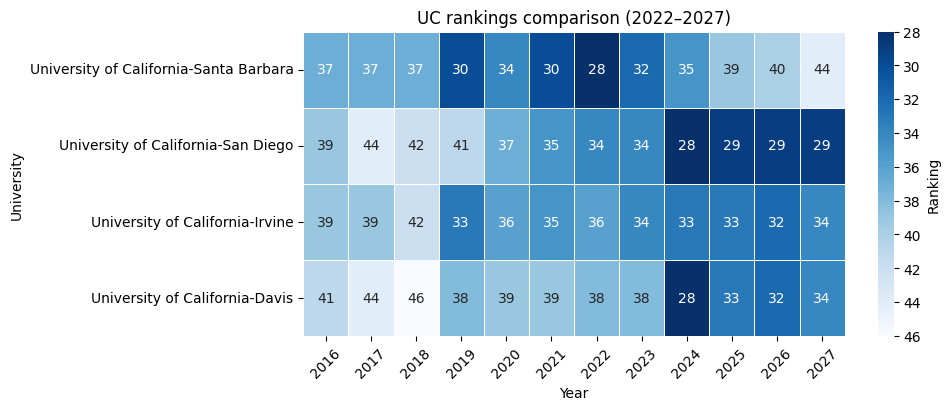

In [ ]:
# Note, data was converted to flourish line race chart for publishing purposes
 
# UCs highlighted 
UC_data = UniversityRankings[
    UniversityRankings['University Name'].str.contains(
        'University of California', case=False, na=False) &
    UniversityRankings['University Name'].str.contains(
        'Santa Barbara|Irvine|San Diego|Davis', case=False, na=False)
].copy()

UC_heatmap = UC_data.set_index('University Name')[years]
UC_heatmap = UC_heatmap.apply(pd.to_numeric, errors='coerce').astype(float)
UC_heatmap = UC_heatmap.sort_values('2022')

plt.figure(figsize=(10, 4))
sec = sns.heatmap(
    UC_heatmap,
    annot=True,
    fmt='.0f',
    cmap='Blues_r',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Ranking'}
)

cbar = sec.collections[0].colorbar
cbar.ax.invert_yaxis()

plt.title('UC rankings comparison (2022–2027)')
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.tight_layout()
plt.xticks(rotation = 45) 
plt.show()

In [ ]:
# Distingushes between private and public schools based on schools iped number 

ipeds = pd.read_csv("hd2024.csv")

# mannual search done to link private and public schools 
# discovered it was sorted in "control"

# Reload the original data to remove duplicate columns
UniversityRankings = pd.read_csv("UniversityRankings.csv")

ipeds = ipeds[['UNITID', 'INSTNM', 'CONTROL']].copy()

# Classify universities
ipeds['Type'] = ipeds['CONTROL'].map({
    1: 'Public',
    2: 'Private Nonprofit',
    3: 'Private For-Profit'
})

# Merge with all universities
UniversityRankings = UniversityRankings.merge(
    ipeds[['UNITID', 'Type']],
    left_on='IPEDS',
    right_on='UNITID',
    how='left',
    validate='many_to_one'
)


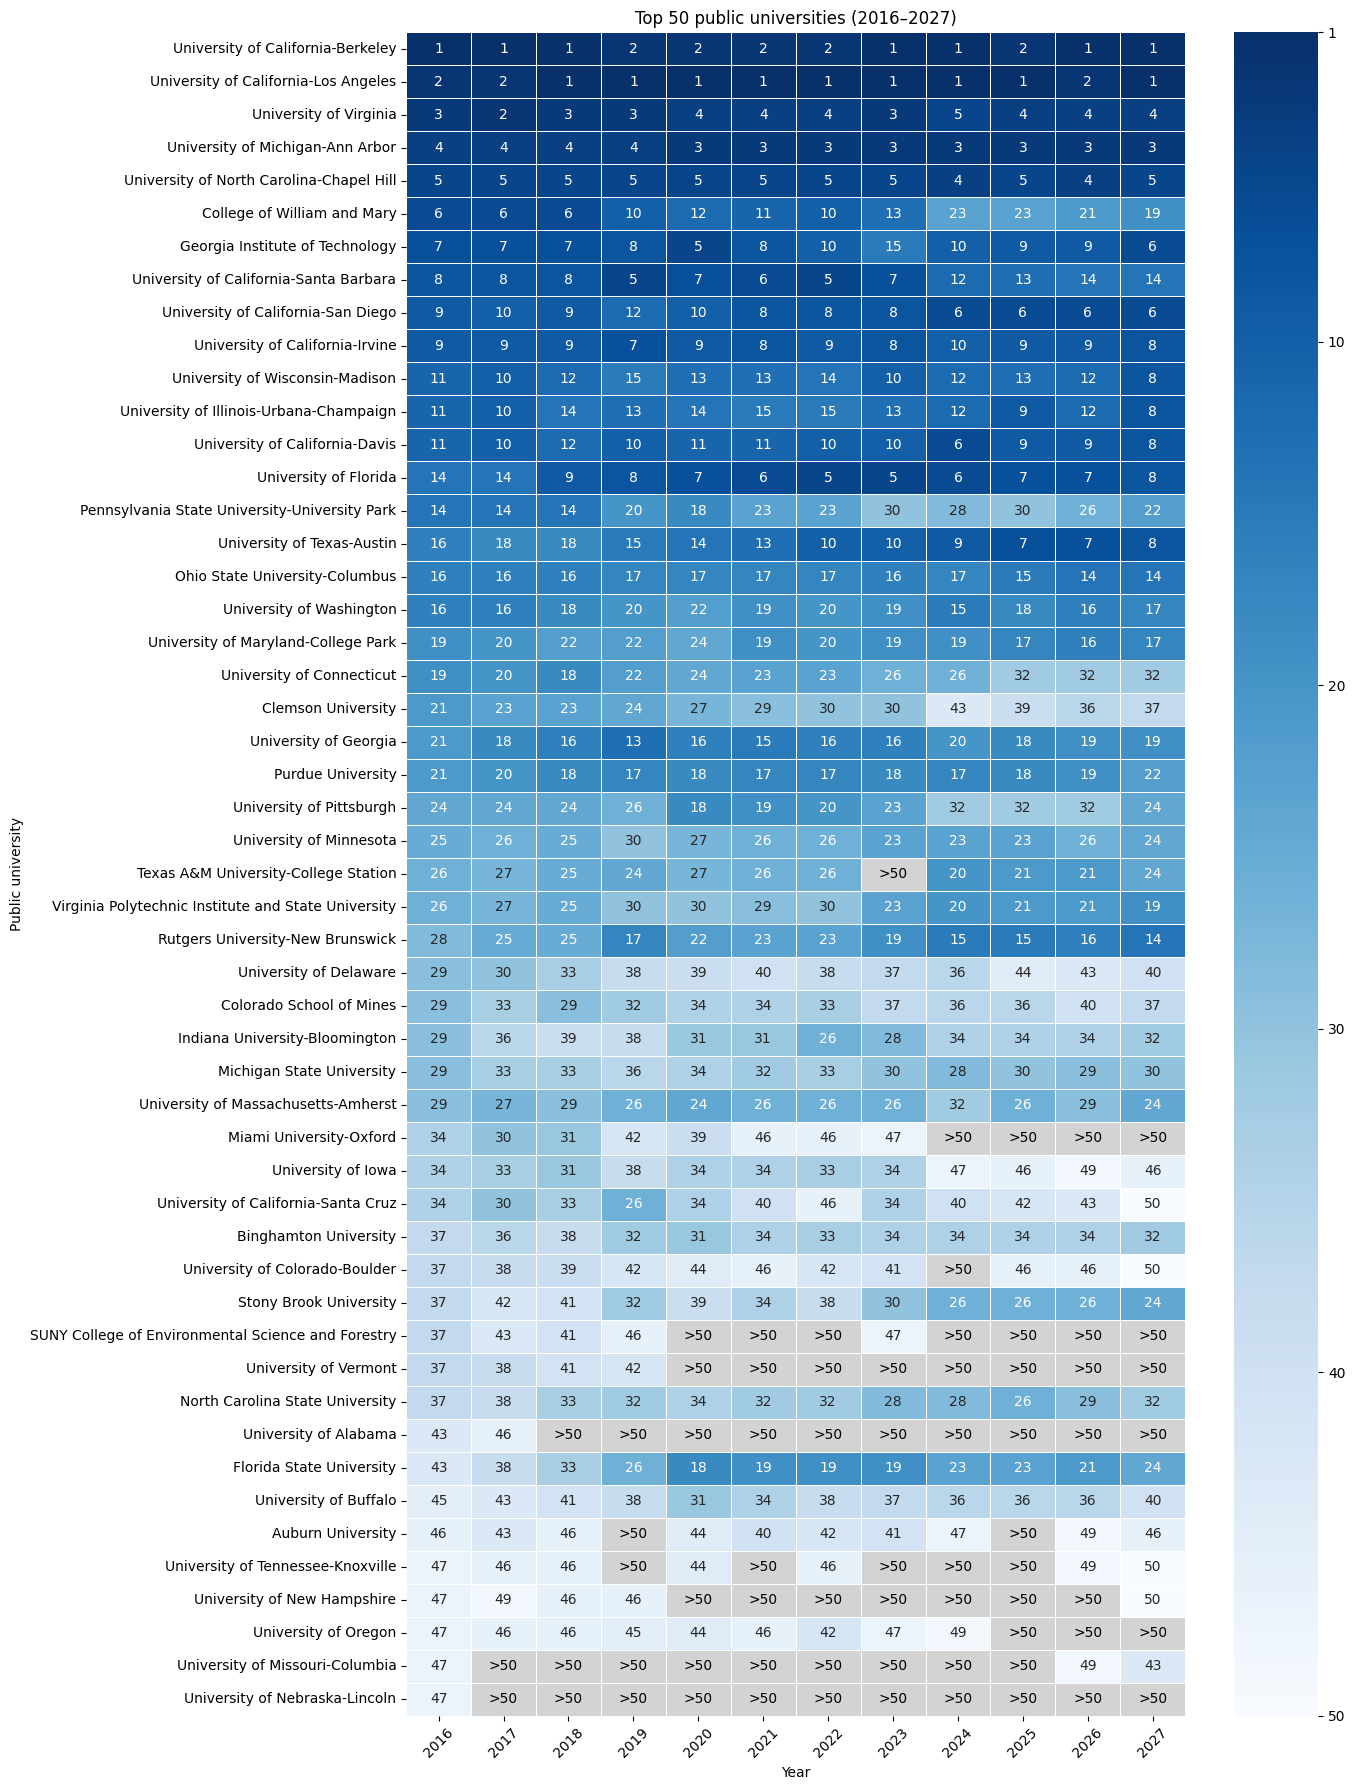

In [ ]:
# Filter for public universities

# Note: converted to java script for publishing purposes 
Public = UniversityRankings[UniversityRankings['Type'] == 'Public'].copy()

years = ['2016', '2017', '2018', '2019', '2020',
         '2021', '2022', '2023', '2024', '2025',
         '2026', '2027']

# Convert rankings to numeric
Public[years] = Public[years].apply(pd.to_numeric, errors='coerce')

# Rank public universities separately for each year
# Universities tied nationally receive the same public ranking
Public[years] = Public[years].rank(method='min', ascending=True)

# Select top 50 public universities based on 2016
Top50Public = Public[Public['2016'] <= 50].copy()

# Prepare heatmap
heatmap_data = Top50Public[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2016')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

# Replace rankings greater than 50 with >50
labels = heatmap_data.map(
    lambda x: '>50' if x > 50 else str(int(x)) if pd.notna(x) else ''
)

# Only color rankings within the top 50
heatmap_colors = heatmap_data.where(heatmap_data <= 50)

# Create heatmap
plt.figure(figsize=(14, 18))

ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='Blues_r',
    vmin=1,
    vmax=50,
    linewidths=0.5
)

 # Fill grey cells with >50
for i in range(len(heatmap_data)):
    for j in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[i, j]) or heatmap_data.iloc[i, j] > 50:
            ax.text(j + 0.5, i + 0.5, '>50',
                    ha='center', va='center', color='black')

# Flip colorbar so rank 1 is on top
cbar = ax.collections[0].colorbar
cbar.ax.invert_yaxis()
cbar.set_ticks([1, 10, 20, 30, 40, 50])

# Grey background for schools ranked >50
ax.set_facecolor('lightgrey')

plt.title('Top 50 public universities (2016–2027)', fontsize=12)
plt.xlabel('Year')
plt.ylabel('Public university')
plt.yticks(rotation=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



                       mean  median  count
Type                                      
Private Nonprofit  2.628571     1.0     35
Public            -2.200000    -4.0     15


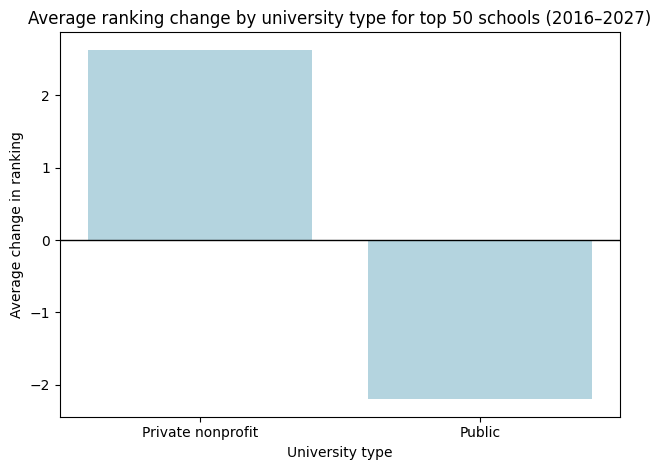

In [ ]:
# private and public in top 50 changes based on 2016-2027 rankings and 2016 top 50
# Note: conveted to floruish for publishing purposes

Top50 = UniversityRankings[UniversityRankings['2016'] <= 50].copy()

Top50['2016'] = pd.to_numeric(Top50['2016'], errors='coerce')

Top50['Ranking_Change'] = Top50['2027'] - Top50['2016']

comparison = Top50.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison)

avg_change = Top50.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average ranking change by university type for top 50 schools (2016–2027)')
plt.xlabel('University type')
plt.ylabel('Average change in ranking')
plt.xticks(ticks=[0, 1], labels=["Private nonprofit", "Public"])
plt.tight_layout()
plt.show()

                       mean  median  count
Type                                      
Private Nonprofit  1.694444     0.0     36
Public            -0.222222    -1.5     18


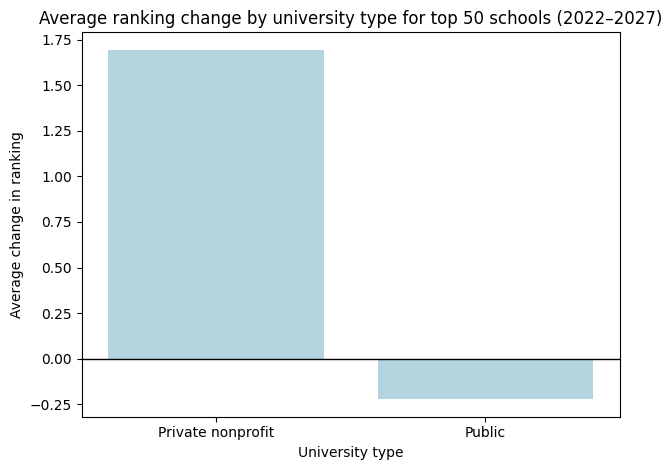

In [ ]:
# private and public in top 50 in 2022, changes to 2027 
# mean vs median count 
# Note: cut from article 
 
Top50 = UniversityRankings[UniversityRankings['2022'] <= 50].copy()

Top50['2022'] = pd.to_numeric(Top50['2022'], errors='coerce')

Top50['Ranking_Change'] = Top50['2027'] - Top50['2022']

comparison = Top50.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison)

avg_change = Top50.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average ranking change by university type for top 50 schools (2022–2027)')
plt.xlabel('University type')
plt.ylabel('Average change in ranking')
plt.xticks(ticks=[0, 1], labels=["Private nonprofit", "Public"])
plt.tight_layout()
plt.show()

                       mean  median  count
Type                                      
Private Nonprofit  8.349206     4.0     63
Public            -4.878788    -6.5     66


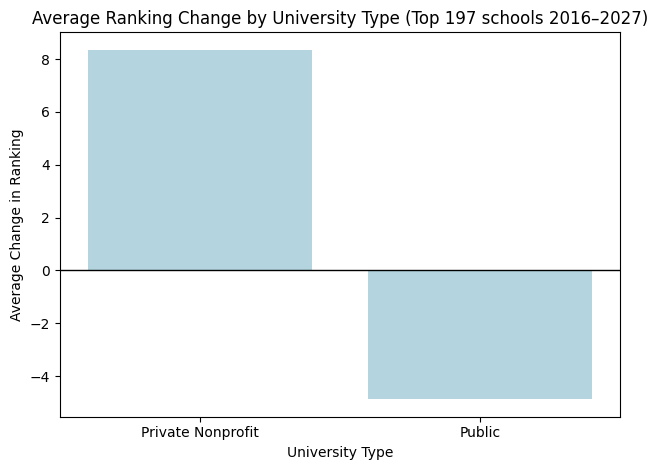

In [ ]:
# private and public changes in all data from 2016 to 2027 
# Note: cut from article 

UR = UniversityRankings.copy()

UR['2016'] = pd.to_numeric(UR['2016'], errors='coerce')
UR['2027'] = pd.to_numeric(UR['2027'], errors='coerce')
UR['Ranking_Change'] = UR['2027'] - UR['2016']

comparison2 = UR.groupby('Type')['Ranking_Change'].agg(
    ['mean', 'median', 'count']
)

print(comparison2)

avg_change2 = UR.groupby('Type', as_index=False)['Ranking_Change'].mean()

sns.barplot(
    data=avg_change2,
    x='Type',
    y='Ranking_Change',
    color='lightblue'
)
plt.axhline(0, color='black', linewidth=1)
plt.title('Average Ranking Change by University Type (Top 197 schools 2016–2027)')
plt.xlabel('University Type')
plt.ylabel('Average Change in Ranking')
plt.tight_layout()
plt.show()

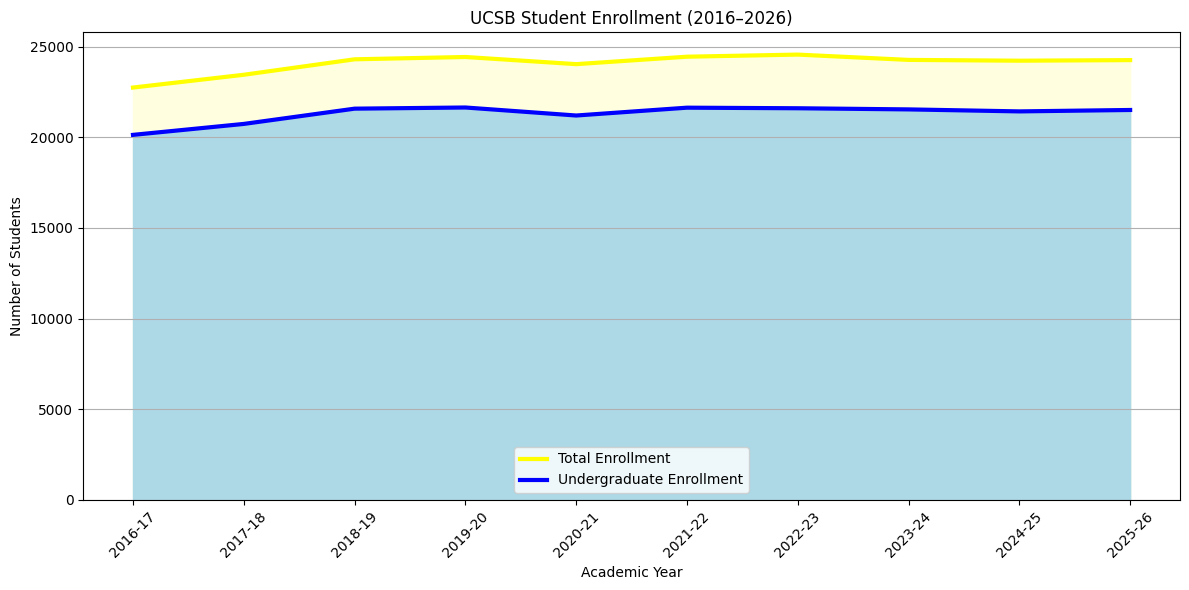

In [ ]:
# UCSB enrollment (undergrad/graduate) 
# Note: made in floruish for publishing reasons 
# https://bap.ucsb.edu/institutional-research/ucsb-information-center/enrollment-dashboard
 


import matplotlib.pyplot as plt
years = [
    "2016-17", "2017-18", "2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24", "2024-25", "2025-26"
]
undergrad = [
    20136, 20740, 21582, 21646, 21204, 21636, 21604, 21541, 21431, 21509
]
total = [
    22746, 23451, 24304, 24432, 24037, 24448, 24564, 24271, 24227, 24260
]

plt.figure(figsize=(12, 6))
plt.fill_between(years, total, color="lightyellow")
plt.fill_between(years, undergrad, color="lightblue")
plt.plot(years, total, color="yellow", linewidth=3, label="Total Enrollment")
plt.plot(years, undergrad, color="blue", linewidth=3, label="Undergraduate Enrollment")
plt.title("UCSB Student Enrollment (2016–2026)")
plt.xlabel("Academic Year")
plt.ylabel("Number of Students")
plt.xticks(rotation=45)
plt.ylim(bottom=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

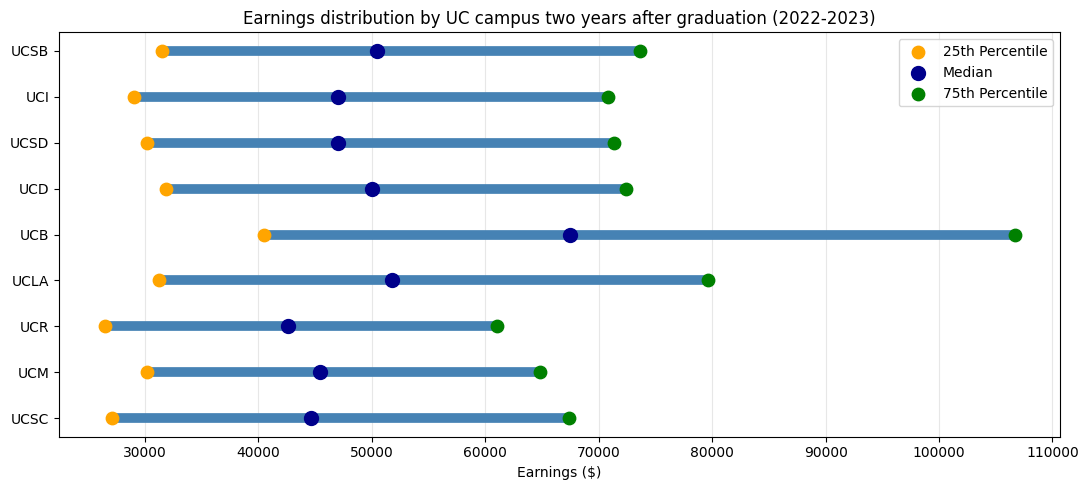

In [ ]:
# Note: made in flourish for publishing reasons 
# Note: second chart for most recent years avaiable also made directly in floruish 

# https://www.universityofcalifornia.edu/about-uc/information-center/uc-alumni-work

import numpy as np 

UCSB = [31550, 50426, 73650]
UCI = [29024, 47074, 70842]
UCSD = [30227, 47048, 71381]
UCD = [31893, 49997, 72425]
UCB = [40488, 67434, 106659]
UCLA = [31223, 51754, 79645]
UCR = [26461, 42596, 61064]
UCM = [30240, 45484, 64816]
UCSC = [27125, 44636, 67372]
schools = ["UCSB", "UCI", "UCSD", "UCD", "UCB", "UCLA", "UCR", "UCM", "UCSC"]
data = [UCSB, UCI, UCSD, UCD, UCB, UCLA, UCR, UCM, UCSC]

p25 = [x[0] for x in data]
median = [x[1] for x in data]
p75 = [x[2] for x in data]

y = np.arange(len(schools))
plt.figure(figsize=(11, 5))
for i in range(len(schools)):
    plt.plot([p25[i], p75[i]], [y[i], y[i]],
             color="steelblue", linewidth=7,
             solid_capstyle="round")

plt.scatter(p25, y, color="orange", s=80,
            label="25th Percentile", zorder=3)
plt.scatter(median, y, color="darkblue", s=100,
            label="Median", zorder=3)
plt.scatter(p75, y, color="green", s=80,
            label="75th Percentile", zorder=3)
plt.yticks(y, schools)
plt.gca().invert_yaxis()
plt.xlabel("Earnings ($)")
plt.title("Earnings distribution by UC campus two years after graduation (2022-2023)")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

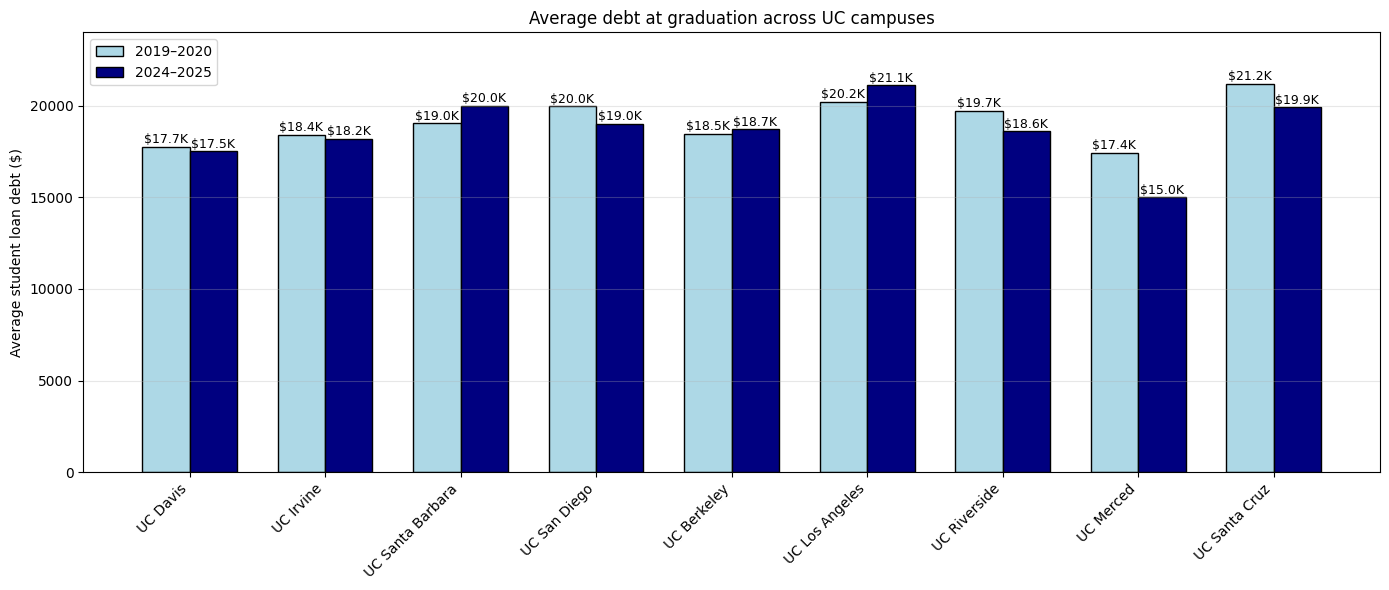

In [ ]:
# Note: cut from article 
# https://accountability.universityofcalifornia.edu/2023/chapters/chapter-2.html
# https://accountability.universityofcalifornia.edu/2024/chapters/chapter-2.html
# https://www.universityofcalifornia.edu/about-uc/information-center/undergraduate-affordability#Comparativedebt




import matplotlib.pyplot as plt
import numpy as np

schools = ["UC Davis", "UC Irvine", "UC Santa Barbara", "UC San Diego",
           "UC Berkeley", "UC Los Angeles", "UC Riverside", "UC Merced",
           "UC Santa Cruz"]

debt_2020 = [17736, 18398, 19034, 19969, 18468, 20200, 19707, 17413, 21189]
debt_2025 = [17500, 18200, 20000, 19000, 18700, 21100, 18600, 15000, 19900]

x = np.arange(len(schools))
width = 0.35

plt.figure(figsize=(14, 6))

bars1 = plt.bar(
    x - width/2, debt_2020, width,
    label="2019–2020", color="lightblue", edgecolor="black"
)

bars2 = plt.bar(
    x + width/2, debt_2025, width,
    label="2024–2025", color="navy", edgecolor="black"
)

# Add shortened dollar labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if np.isfinite(height):
            plt.text(
                bar.get_x() + bar.get_width()/2,
                height + 200,
                f"${height/1000:.1f}K",
                ha="center",
                fontsize=9
            )

plt.xticks(x, schools, rotation=45, ha="right")
plt.ylabel("Average student loan debt ($)")
plt.title("Average debt at graduation across UC campuses")
plt.ylim(0, 24000)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#Data quality check for UC schools finantial stats 

import pandas as pd
import numpy as np
import re
import html


# clean

FILE = "Data_11-5-2026.csv"

df = pd.read_csv(FILE, encoding="utf-8-sig", low_memory=False)

df.columns = [
    re.sub(r"^\*+", "", html.unescape(str(c))).strip()
    for c in df.columns
]

print("DATASET OVERVIEW")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicate column names:", df.columns.duplicated().sum())

issues = []
summary = []

def report(check, status, detail):
    summary.append({
        "check": check,
        "status": status,
        "detail": detail
    })

def issue(year, school, field, problem, value=None):
    issues.append({
        "year": year,
        "school": school,
        "field": field,
        "problem": problem,
        "value": value
    })

#campuses
uc_campuses = {
    110635: "Berkeley",
    110644: "Davis",
    110653: "Irvine",
    110662: "Los Angeles",
    445188: "Merced",
    110671: "Riverside",
    110680: "San Diego",
    110705: "Santa Barbara",
    110714: "Santa Cruz"
}

if "UnitID" not in df.columns:
    raise ValueError("Missing UnitID column")

df["UnitID"] = pd.to_numeric(df["UnitID"], errors="coerce")
uc = df[df["UnitID"].isin(uc_campuses)].copy()

found = set(uc["UnitID"].dropna().astype(int))
missing_schools = set(uc_campuses) - found

report(
    "Nine UC campuses",
    "PASS" if not missing_schools and len(uc) == 9 else "FAIL",
    f"Found {len(uc)} rows; missing IDs: {sorted(missing_schools)}"
)

duplicates = uc[uc.duplicated("UnitID", keep=False)]

report(
    "Duplicate UC UnitIDs",
    "PASS" if duplicates.empty else "FAIL",
    f"{len(duplicates)} duplicate rows"
)

#year and cilumn mapping

years = {
    2020: ("F1920_F1A_RV", "EFIA2020_RV"),
    2021: ("F2021_F1A_RV", "EFIA2021_RV"),
    2022: ("F2122_F1A_RV", "EFIA2022_RV"),
    2023: ("F2223_F1A_RV", "EFIA2023_RV"),
    2024: ("F2324_F1A", "EFIA2024_RV")
}

expenses = {
    "instruction": "Instruction - Current year total",
    "research": "Research - Current year total",
    "public_service": "Public service - Current year total",
    "academic_support": "Academic support - Current year total",
    "student_services": "Student services - Current year total",
    "institutional_support": "Institutional support - Current year total"
}

enrollment = {
    "ug_fte": "Estimated full-time equivalent (FTE) undergraduate enrollment",
    "grad_fte": "Estimated full-time equivalent (FTE) graduate enrollment",
    "doctor_fte": "Reported full-time equivalent (FTE) doctors professional practice"
}

def find_column(prefix, code, flag=False):
    if flag:
        prefix = "Imputation/Status Flag For " + prefix

    matches = [
        c for c in uc.columns
        if c.startswith(prefix)
        and c.endswith(f"({code})")
    ]

    if len(matches) != 1:
        return None

    return matches[0]

#check values

long_data = []
flag_data = []

for year, (finance_code, enroll_code) in years.items():

    x = uc[["UnitID", "Institution Name"]].copy()
    x["year"] = year

    all_fields = [
        (key, prefix, finance_code)
        for key, prefix in expenses.items()
    ] + [
        (key, prefix, enroll_code)
        for key, prefix in enrollment.items()
    ]

    for key, prefix, code in all_fields:

        col = find_column(prefix, code)
        flag_col = find_column(prefix, code, flag=True)

        if col is None:
            report(
                f"{year} {key} column",
                "FAIL",
                "Required column missing or ambiguous"
            )
            x[key] = np.nan
            continue

        report(
            f"{year} {key} column",
            "PASS",
            col
        )

        raw = uc[col].astype("string").str.strip()

        numeric = pd.to_numeric(
            raw.str.replace(",", "", regex=False),
            errors="coerce"
        )

        x[key] = numeric

        for idx in uc.index:
            school = uc.at[idx, "Institution Name"]
            original = raw.loc[idx]
            value = numeric.loc[idx]

            if pd.isna(value):
                issue(
                    year, school, key,
                    "Missing or nonnumeric",
                    str(original)
                )

            elif value < 0:
                issue(
                    year, school, key,
                    "Negative value",
                    value
                )

            elif key.endswith("_fte") and value == 0:
                issue(
                    year, school, key,
                    "Zero enrollment; verify applicability",
                    value
                )

        if flag_col is None:
            report(
                f"{year} {key} status flag",
                "WARN",
                "Flag column missing or ambiguous"
            )
        else:
            for idx in uc.index:
                flag_data.append({
                    "year": year,
                    "school": uc.at[idx, "Institution Name"],
                    "field": key,
                    "status_flag": uc.at[idx, flag_col],
                    "value": numeric.loc[idx]
                })

    #check relationships 

    if all(k in x.columns for k in enrollment):

        x["total_fte"] = (
            x["ug_fte"]
            + x["grad_fte"]
            + x["doctor_fte"]
        )

        x["ug_share"] = (
            x["ug_fte"] / x["total_fte"]
        )

        for _, row in x.iterrows():

            if pd.notna(row["total_fte"]):

                if row["total_fte"] <= 0:
                    issue(
                        year, row["Institution Name"],
                        "total_fte",
                        "Nonpositive total FTE",
                        row["total_fte"]
                    )

                if (
                    pd.notna(row["ug_share"])
                    and not 0 <= row["ug_share"] <= 1
                ):
                    issue(
                        year, row["Institution Name"],
                        "ug_share",
                        "Undergraduate share outside 0-1",
                        row["ug_share"]
                    )

    long_data.append(x)

#check yearly changes

long_df = pd.concat(long_data, ignore_index=True)

long_df = long_df.sort_values(
    ["UnitID", "year"]
)

fields_to_check = list(expenses) + list(enrollment)

for field in fields_to_check:

    # Percentage change from previous year
    previous = long_df.groupby("UnitID")[field].shift(1)

    change = (
        (long_df[field] - previous)
        / previous.replace(0, np.nan)
    )

    long_df[field + "_pct_change"] = change * 100

    # Flag unusually large changes, not errors
    large = change.abs() > 0.50

    for _, row in long_df[large].iterrows():
        issue(
            row["year"],
            row["Institution Name"],
            field,
            "Year-over-year change exceeds 50%",
            round(row[field + "_pct_change"], 2)
        )

#check distributions

flags = pd.DataFrame(flag_data)

if not flags.empty:

    print("\nIPEDS STATUS FLAG DISTRIBUTION")

    flag_summary = (
        flags.groupby(
            ["year", "field", "status_flag"],
            dropna=False
        )
        .size()
        .reset_index(name="count")
    )

    print(flag_summary.to_string(index=False))

else:
    flag_summary = pd.DataFrame(
        columns=["year", "field", "status_flag", "count"]
    )

#export reports

summary_df = pd.DataFrame(summary)
issues_df = pd.DataFrame(issues)

if issues_df.empty:
    issues_df = pd.DataFrame(
        columns=["year", "school", "field", "problem", "value"]
    )

summary_df.to_csv(
    "uc_ipeds_audit_summary.csv",
    index=False
)

issues_df.to_csv(
    "uc_ipeds_audit_issues.csv",
    index=False
)

flag_summary.to_csv(
    "uc_ipeds_status_flags.csv",
    index=False
)

long_df.to_csv(
    "uc_ipeds_audit_long_data.csv",
    index=False
)

#report results

print("\n" + "=" * 50)
print("FINAL DATA QUALITY AUDIT")
print("=" * 50)

print("UC campuses:", uc["UnitID"].nunique())
print("Years:", sorted(years))
print("Expected campus-year records:", 45)
print("Actual campus-year records:", len(long_df))

print("\nColumn check results:")
print(summary_df["status"].value_counts())

print("\nIssues by type:")
if issues_df.empty:
    print("No issues detected")
else:
    print(issues_df["problem"].value_counts())

print("\nFiles created:")
print("uc_ipeds_audit_summary.csv")
print("uc_ipeds_audit_issues.csv")
print("uc_ipeds_status_flags.csv")
print("uc_ipeds_audit_long_data.csv")

print("\nAudit complete. Original CSV unchanged.")


DATASET OVERVIEW
Rows: 9
Columns: 93
Duplicate column names: 0

IPEDS STATUS FLAG DISTRIBUTION
 year                 field status_flag  count
 2020      academic_support           R      9
 2020            doctor_fte           A      3
 2020            doctor_fte           R      6
 2020              grad_fte           G      9
 2020 institutional_support           R      9
 2020           instruction           R      9
 2020        public_service           R      9
 2020              research           R      9
 2020      student_services           R      9
 2020                ug_fte           G      9
 2021      academic_support           R      9
 2021            doctor_fte           A      3
 2021            doctor_fte           R      6
 2021              grad_fte           G      9
 2021 institutional_support           R      9
 2021           instruction           R      9
 2021        public_service           R      9
 2021              research           R      9
 2021      s

In [ ]:

import pandas as pd
import numpy as np

#data from audit 

data = long_df.copy()

# Get the original IPEDS doctoral FTE flags
doctor_flags = flags[
    flags["field"] == "doctor_fte"
][["year", "school", "status_flag"]].copy()

doctor_flags = doctor_flags.rename(
    columns={"status_flag": "doctor_fte_flag"}
)

data = data.merge(
    doctor_flags,
    left_on=["year", "Institution Name"],
    right_on=["year", "school"],
    how="left",
    validate="one_to_one"
)

data = data.drop(columns=["school"])

#fix doctoral FTE values based on IPEDS flags

# IPEDS flag A = Not applicable
# Only replace missing values marked A

not_applicable = (
    data["doctor_fte"].isna()
    & data["doctor_fte_flag"].eq("A")
)

print("Doctoral FTE values treated as zero:",
      not_applicable.sum())

data.loc[not_applicable, "doctor_fte"] = 0

#verify data 

required = [
    "instruction",
    "research",
    "public_service",
    "academic_support",
    "student_services",
    "institutional_support",
    "ug_fte",
    "grad_fte",
    "doctor_fte"
]

if data[required].isna().any().any():
    raise ValueError(
        "Unresolved missing values remain:\n"
        + data.loc[
            data[required].isna().any(axis=1),
            ["Institution Name", "year"] + required
        ].to_string(index=False)
    )

if (data[required] < 0).any().any():
    raise ValueError("Negative spending or FTE values detected")

if len(data) != 45:
    raise ValueError("Expected exactly 45 campus-year records")

if data.duplicated(["UnitID", "year"]).any():
    raise ValueError("Duplicate campus-year records detected")

#calc fte

data["total_fte"] = (
    data["ug_fte"]
    + data["grad_fte"]
    + data["doctor_fte"]
)

if (data["total_fte"] <= 0).any():
    raise ValueError("Invalid total FTE detected")

#calc undergrad share

data["ug_share"] = (
    data["ug_fte"] / data["total_fte"]
)
#research and public service adjusted by undergrad share

data["adjusted_research"] = (
    data["research"] * data["ug_share"]
)

data["adjusted_public_service"] = (
    data["public_service"] * data["ug_share"]
)

#adjust academic soending 

data["adjusted_spending"] = (
    data["instruction"]
    + data["academic_support"]
    + data["student_services"]
    + data["institutional_support"]
    + data["adjusted_research"]
    + data["adjusted_public_service"]
)

#finantial resorces per student 

data["spending_per_student"] = (
    data["adjusted_spending"] / data["total_fte"]
)

# Natural log (not the final U.S. News score)
data["log_spending"] = np.where(
    data["spending_per_student"] > 0,
    np.log(data["spending_per_student"].clip(lower=1e-10)),
    np.nan
)

#print

results = data[
    [
        "Institution Name",
        "year",
        "total_fte",
        "ug_share",
        "adjusted_spending",
        "spending_per_student"
    ]
].sort_values(["Institution Name", "year"])

print("\nFINANCIAL RESOURCES PER STUDENT")
print(results.to_string(index=False))

#export 
data.to_csv(
    "uc_financial_resources_detailed.csv",
    index=False
)


flourish = data.pivot(
    index="Institution Name",
    columns="year",
    values="spending_per_student"
)

flourish = flourish.round(2).reset_index()
flourish.columns.name = None

flourish.to_csv(
    "uc_financial_resources_flourish.csv",
    index=False
)

print("\nFLOURISH TABLE")
print(flourish.to_string(index=False))

print("\nCalculation completed successfully.")
print("Files exported:")
print("uc_financial_resources_detailed.csv")
print("uc_financial_resources_flourish.csv")


Doctoral FTE values treated as zero: 15

FINANCIAL RESOURCES PER STUDENT
                      Institution Name  year  total_fte  ug_share  adjusted_spending  spending_per_student
     University of California-Berkeley  2020    44195.0   0.72696  2314270833.635366          52364.992276
     University of California-Berkeley  2021    44384.0  0.738937  2296843183.890343          51749.350755
     University of California-Berkeley  2022    45872.0  0.711414  2497195039.563786          54438.329255
     University of California-Berkeley  2023    45637.0  0.722615  2617119717.363324          57346.445151
     University of California-Berkeley  2024    46344.0  0.730148  2877484355.858623          62089.684875
        University of California-Davis  2020    38622.0  0.801383   2306528032.06416          59720.574596
        University of California-Davis  2021    39803.0  0.800291  2403392015.706857          60382.182642
        University of California-Davis  2022    39871.0  0.790198  2630

In [10]:

import pandas as pd

# ==========================================
# 1. LOAD DATA
# ==========================================

# IPEDS faculty salaries
salary = pd.read_csv("Data_11-5-2026_2.csv")

# BEA Regional Price Parities (first 3 lines are descriptions)
bea = pd.read_csv("faculty_sal.csv", skiprows=3)

# Clean column names
salary.columns = salary.columns.str.strip().str.replace("**", "", regex=False)
bea.columns = bea.columns.str.strip().str.replace("**", "", regex=False)

# ==========================================
# 2. KEEP BEA ALL-ITEMS RPP
# ==========================================

bea["LineCode"] = pd.to_numeric(bea["LineCode"], errors="coerce")
bea = bea[bea["LineCode"] == 1].copy()

# ==========================================
# 3. MATCH UC CAMPUSES TO METRO AREAS
# ==========================================

uc_metros = {
    "UC Berkeley": (
        "University of California-Berkeley",
        "San Francisco-Oakland"
    ),
    "UC Davis": (
        "University of California-Davis",
        "Sacramento"
    ),
    "UC Irvine": (
        "University of California-Irvine",
        "Los Angeles-Long Beach"
    ),
    "UC Los Angeles": (
        "University of California-Los Angeles",
        "Los Angeles-Long Beach"
    ),
    "UC Merced": (
        "University of California-Merced",
        "Merced,"
    ),
    "UC Riverside": (
        "University of California-Riverside",
        "Riverside-San Bernardino"
    ),
    "UC San Diego": (
        "University of California-San Diego",
        "San Diego-"
    ),
    "UC Santa Barbara": (
        "University of California-Santa Barbara",
        "Santa Maria-Santa Barbara"
    ),
    "UC Santa Cruz": (
        "University of California-Santa Cruz",
        "Santa Cruz-"
    )
}

# ==========================================
# 4. CALCULATE ADJUSTED FACULTY SALARIES
# ==========================================

results = []

for uc, (institution, metro_name) in uc_metros.items():

    # Find university in IPEDS
    school_match = salary[
        salary["Institution Name"].astype(str).str.strip().str.casefold()
        == institution.casefold()
    ]

    # Find corresponding metro in BEA
    metro_match = bea[
        bea["GeoName"].astype(str).str.contains(
            metro_name,
            case=False,
            na=False,
            regex=False
        )
    ]

    if len(school_match) != 1 or len(metro_match) != 1:
        print(
            f"Skipping {uc}: "
            f"school matches={len(school_match)}, "
            f"metro matches={len(metro_match)}"
        )
        continue

    school = school_match.iloc[0]
    metro = metro_match.iloc[0]

    for year in range(2020, 2025):

        # Locate the IPEDS salary column for this year
        salary_columns = [
            col for col in salary.columns
            if col.startswith(
                "Average salary for instructional staff "
                "equated to a 9-month contract-total"
            )
            and f"SAL{year}_IS" in col
            and not col.startswith("Imputation/Status Flag")
        ]

        if len(salary_columns) != 1:
            print(f"Missing salary column: {uc}, {year}")
            continue

        # Average faculty salary standardized to 9 months
        raw_salary = pd.to_numeric(
            school[salary_columns[0]],
            errors="coerce"
        )

        # BEA Regional Price Parity
        rpp = pd.to_numeric(
            metro[str(year)],
            errors="coerce"
        )

        # U.S. News-style cost-of-living adjustment
        if pd.notna(raw_salary) and pd.notna(rpp) and rpp > 0:
            adjusted_salary = raw_salary / (rpp / 100)
        else:
            adjusted_salary = float("nan")

        results.append({
            "school": uc,
            "year": year,
            "metro": metro["GeoName"],
            "raw_salary": raw_salary,
            "rpp": rpp,
            "adjusted_salary": adjusted_salary
        })

# ==========================================
# 5. CREATE DATAFRAMES
# ==========================================

df = pd.DataFrame(results)

if df.empty:
    raise ValueError(
        "No results were created. Check university and metro names."
    )

df = df.sort_values(["school", "year"])

# ==========================================
# 6. CREATE FLOURISH TABLE
# ==========================================

flourish = df.pivot(
    index="year",
    columns="school",
    values="adjusted_salary"
).reset_index()

flourish.columns.name = None
flourish = flourish.round(2)

# ==========================================
# 7. DISPLAY RESULTS
# ==========================================

print("DETAILED FACULTY SALARIES:")
display(df)

print("FLOURISH TABLE:")
display(flourish)

# ==========================================
# 8. EXPORT CSV FILES
# ==========================================

df.to_csv(
    "uc_faculty_salaries_detailed.csv",
    index=False
)

flourish.to_csv(
    "uc_faculty_salaries_flourish.csv",
    index=False
)

print("Both CSV files saved successfully!")


Skipping UC Merced: school matches=1, metro matches=0
DETAILED FACULTY SALARIES:


,school,year,metro,raw_salary,rpp,adjusted_salary
0,UC Berkeley,2020,"San Francisco-Oakland-Fremont, CA (Metropolita...",163401,119.582,136643.474770
1,UC Berkeley,2021,"San Francisco-Oakland-Fremont, CA (Metropolita...",170122,120.038,141723.454239
2,UC Berkeley,2022,"San Francisco-Oakland-Fremont, CA (Metropolita...",175852,118.003,149023.329915
3,UC Berkeley,2023,"San Francisco-Oakland-Fremont, CA (Metropolita...",182654,117.551,155382.770032
4,UC Berkeley,2024,"San Francisco-Oakland-Fremont, CA (Metropolita...",192150,115.613,166201.032756
5,UC Davis,2020,"Sacramento-Roseville-Folsom, CA (Metropolitan ...",138585,106.957,129570.762082
6,UC Davis,2021,"Sacramento-Roseville-Folsom, CA (Metropolitan ...",143378,106.271,134917.333986
7,UC Davis,2022,"Sacramento-Roseville-Folsom, CA (Metropolitan ...",151148,109.904,137527.296550
8,UC Davis,2023,"Sacramento-Roseville-Folsom, CA (Metropolitan ...",159262,109.091,145990.045008
9,UC Davis,2024,"Sacramento-Roseville-Folsom, CA (Metropolitan ...",165182,106.670,154853.285835


FLOURISH TABLE:


,year,UC Berkeley,UC Davis,UC Irvine,UC Los Angeles,UC Riverside,UC San Diego,UC Santa Barbara,UC Santa Cruz
0,2020,136643.47,129570.76,130303.64,153745.92,123553.69,129414.47,135823.24,122710.43
1,2021,141723.45,134917.33,131975.19,155611.43,126077.32,132327.43,142126.02,128105.32
2,2022,149023.33,137527.30,139650.33,166233.63,132019.34,138358.20,148076.80,128039.43
3,2023,155382.77,145990.05,143177.72,172337.89,136659.80,149989.62,156686.63,135306.90
4,2024,166201.03,154853.29,152952.47,182657.66,144567.93,153751.55,171048.18,147396.63


Both CSV files saved successfully!
